# Compute mouse pseudotime for one timepoint (fib/dec) — for SAMap transfer

Per-timepoint mouse fibroblast/decidual trajectory: subset -> (optional) drop apoptotic ->
fresh scVI -> neighbors -> diffmap -> DPT with a chosen root -> spatial viz. Writes an object
whose `obs_names` are **bare mouse barcodes** with a `dpt_pseudotime` column, which is the exact
contract `kara_rings_figure` reads to transfer pt onto human via SAMap.

**Judgment lives in two cells (marked ⚑):** the root choice and the apoptotic filter. Both are
built to *show you the evidence* before you commit, because a wrong root or a spurious apoptotic
branch quietly produces a plausible-but-wrong ordering.

**Kernel:** scVI needs the compute — use the samap env (has scvi/scanpy) with
`module load gcc/14.2.0-fasrc01` before launch, or whatever env has `scvi-tools`. GPU strongly
preferred for scVI; CPU works but is slow.

## Config

In [1]:
%matplotlib inline
import os, numpy as np, pandas as pd, scanpy as sc, anndata as ad
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
sc.settings.verbosity = 1

# ---------------- CONFIG ----------------
REFINED   = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/interim/refined_mouse.h5ad"
OUTDIR    = "/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/pseudotime"

TIMEPOINT = "1_dpi_late"     # ⇐ one of refined_mouse's obs['timepoint'] values
STAGE_TAG = "1dpi"               # ⇐ the token kara_rings_figure expects -> writes adata_<STAGE_TAG>.h5ad
#   secretory pairing -> TIMEPOINT="1_dpi_late", STAGE_TAG="1dpi_late"

COARSE_COL, FINE_COL, TP_COL = "coarse_refined", "fine_refined", "timepoint"
FIBDEC = {"decidual cells", "endometrial fibroblasts"}

# scVI
N_LATENT, N_HVG, MAX_EPOCHS = 30, 3000, 400
N_NEIGHBORS = 15

# ⚑ apoptotic filter (toggle + threshold set in its own cell below)
REMOVE_APOPTOTIC = False
APOPTOSIS_GENES  = ["Casp3","Casp8","Casp9","Bax","Bak1","Bbc3","Pmaip1","Cycs",
                    "Apaf1","Bid","Fas","Tnfrsf10b","Gadd45a","Ddit3"]   # edit to taste
APOP_QUANTILE    = 0.90          # cells above this score quantile dropped (if REMOVE_APOPTOTIC)

os.makedirs(OUTDIR, exist_ok=True)
OUT_H5AD = f"{OUTDIR}/adata_{STAGE_TAG}.h5ad"
print("will write ->", OUT_H5AD)

will write -> /n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/pseudotime/adata_1dpi.h5ad


## 1. Load + subset to this timepoint's fib/dec cells

Uses raw counts (scVI wants counts). `refined_mouse.X` is log-normalized, so we pull counts from
`layers['counts']`.

In [2]:
a = ad.read_h5ad(REFINED)
for col in (COARSE_COL, FINE_COL, TP_COL):
    assert col in a.obs.columns, f"missing obs col {col}; have {list(a.obs.columns)}"
a

AnnData object with n_obs × n_vars = 57033 × 33698
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'hvg', 'leiden_scVI_0.1', 'leiden_scVI_0.2', 'leiden_scVI_0.3', 'leiden_scVI_0.4', 'leiden_scVI_0.5', 'leiden_scVI_0.6', 'leiden_scVI_0.7', 'leiden_scVI_0.8', 'leiden_scVI_0.9', 'leiden_scVI_1.0', 'leiden_scVI_1.5', 'leiden_scVI_10.0', 'leiden_scVI_2.0', 'leiden_scVI_2.5', 'leiden_scVI_3.0', 'leiden_scVI_3.0_colors', 'leiden_scVI_4.0', 'leiden_scVI_5.0', 'leiden_scVI_6.0', 'leiden_scVI_7.0', 'leiden_scVI_8.0', 'leiden_scVI_9.0', 'log1p', 'neighbors_scVI_100', 'timepoint_colors', 'umap'
    obsm: 'spatial'
    layers: 'counts'

In [3]:
keep = (a.obs[COARSE_COL].astype(str).isin(FIBDEC).values) & (a.obs[TP_COL].astype(str) == TIMEPOINT)

a = a[keep].copy()
a = a[~(a.obs['fine_refined'] == 'decAp')].copy()

print(f"{TIMEPOINT}: {a.n_obs} fib/dec cells")
print("subtypes:", dict(list(a.obs[FINE_COL].value_counts().items())[:12]))

# scVI needs raw counts in .X
assert "counts" in a.layers, f"no counts layer; have {list(a.layers)}"
a.X = a.layers["counts"].copy()
a.layers["logcounts"] = a.layers.get("counts")  # keep a copy path; we re-log later for scoring
del a.layers["counts"]
print("X now counts; max =", float(a.X.max()))

1_dpi_late: 10656 fib/dec cells
subtypes: {'dec2': 3818, 'eFib2i': 3734, 'dec1': 1233, 'eFib3': 724, 'dec3': 472, 'eFib1': 362, 'eFibP': 161, 'eFib2': 152}
X now counts; max = 2031.0


## 2. ⚑ Apoptotic filter (optional) — run WITH and WITHOUT to see if pt changes

Scores an apoptosis panel on log-normalized data, shows the distribution, and (if enabled) drops the
top-quantile cells. Apoptotic cells often form a spurious DPT branch — the honest move is to compare
the trajectory with and without, not to assume.

apoptosis genes present: 14/14 -> ['Casp3', 'Casp8', 'Casp9', 'Bax', 'Bak1', 'Bbc3', 'Pmaip1', 'Cycs', 'Apaf1', 'Bid', 'Fas', 'Tnfrsf10b', 'Gadd45a', 'Ddit3']


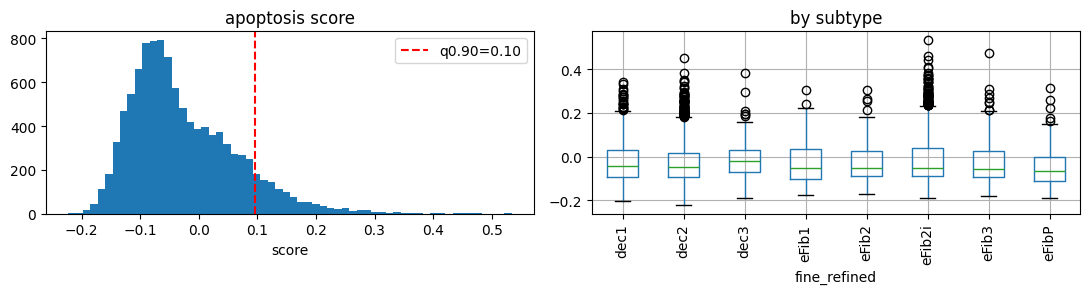

REMOVE_APOPTOTIC=False — keeping all cells (flip to True to experiment)


In [4]:
# score on a temporary log-normalized copy (don't disturb the counts in .X)
tmp = a.copy(); sc.pp.normalize_total(tmp, target_sum=1e4); sc.pp.log1p(tmp)
present = [g for g in APOPTOSIS_GENES if g in tmp.var_names]
print(f"apoptosis genes present: {len(present)}/{len(APOPTOSIS_GENES)} -> {present}")
sc.tl.score_genes(tmp, present, score_name="apop_score")
a.obs["apop_score"] = tmp.obs["apop_score"].values

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(a.obs["apop_score"], bins=60); ax[0].set_title("apoptosis score"); ax[0].set_xlabel("score")
thr = np.quantile(a.obs["apop_score"], APOP_QUANTILE)
ax[0].axvline(thr, color="r", ls="--", label=f"q{APOP_QUANTILE:.2f}={thr:.2f}"); ax[0].legend()
# score by subtype so you can see if apoptosis tracks a biological group vs is diffuse
a.obs.boxplot("apop_score", by=FINE_COL, ax=ax[1], rot=90); ax[1].set_title("by subtype"); plt.suptitle("")
plt.tight_layout(); plt.show()

if REMOVE_APOPTOTIC:
    before = a.n_obs
    a = a[a.obs["apop_score"] < thr].copy()
    print(f"dropped {before - a.n_obs} apoptotic cells (>{APOP_QUANTILE} quantile); {a.n_obs} remain")
else:
    print("REMOVE_APOPTOTIC=False — keeping all cells (flip to True to experiment)")

## 3. Fresh scVI embedding on this subset

In [5]:
import scvi

# HVGs on counts, then TRAIN on the HVG subset (not the full gene set)
sc.pp.highly_variable_genes(a, n_top_genes=N_HVG, flavor="seurat_v3", subset=False)
a_hvg = a[:, a.var["highly_variable"]].copy()      # ~N_HVG genes, counts in .X
print(f"training scVI on {a_hvg.n_vars} HVGs")

scvi.model.SCVI.setup_anndata(a_hvg, layer=None)   # a_hvg.X holds counts
model = scvi.model.SCVI(a_hvg, n_latent=N_LATENT)
model.train(max_epochs=MAX_EPOCHS, early_stopping=True)

# transfer the latent back to the FULL object (same cell order -> direct assign)
a.obsm["X_scVI"] = model.get_latent_representation(a_hvg)
print("X_scVI:", a.obsm["X_scVI"].shape)

# re-log the full object's .X for downstream viz/scoring (keep counts in a layer)
a.layers["counts"] = a.X.copy()
sc.pp.normalize_total(a, target_sum=1e4); sc.pp.log1p(a)

training scVI on 3000 HVGs


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A40') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/400 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=400` reached.


X_scVI: (10656, 30)


## 4. Neighbors + diffusion map + UMAP (on the scVI space)

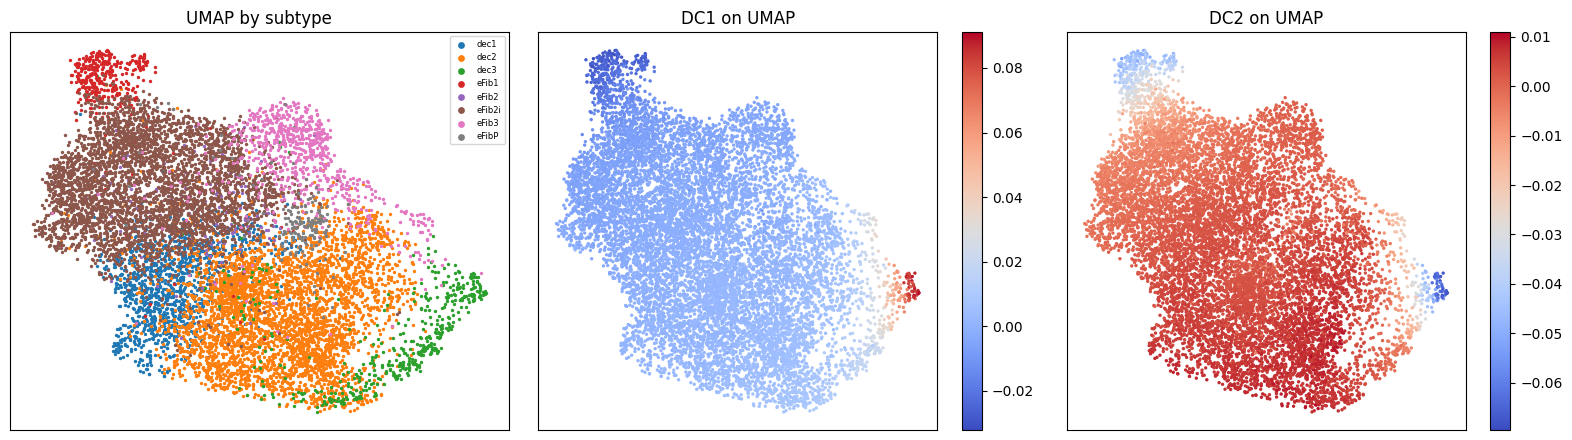

In [6]:
sc.pp.neighbors(a, use_rep="X_scVI", n_neighbors=N_NEIGHBORS)
sc.tl.umap(a)
sc.tl.diffmap(a, n_comps=15)

# quick look: subtype on UMAP + the diffusion components we'll root against
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for i, comp in enumerate([("umap", None), ("diffmap", 1), ("diffmap", 2)]):
    basis, dc = comp
    if basis == "umap":
        for j, s in enumerate(sorted(a.obs[FINE_COL].astype(str).unique())):
            m = (a.obs[FINE_COL].astype(str) == s).values
            ax[i].scatter(a.obsm["X_umap"][m,0], a.obsm["X_umap"][m,1], s=6, label=s, linewidths=0)
        ax[i].legend(fontsize=6, markerscale=2); ax[i].set_title("UMAP by subtype")
    else:
        sc_ = ax[i].scatter(a.obsm["X_umap"][:,0], a.obsm["X_umap"][:,1],
                            c=a.obsm["X_diffmap"][:, dc], s=6, cmap="coolwarm", linewidths=0)
        ax[i].set_title(f"DC{dc} on UMAP"); plt.colorbar(sc_, ax=ax[i])
    ax[i].set_xticks([]); ax[i].set_yticks([])
plt.tight_layout(); plt.show()

## 5. ⚑ Pick the root — extreme-DC cell, THEN verify it's biologically the fibroblast end

Two candidates are computed: the DC-extreme cell (geometric) and, if you set `ROOT_SUBTYPE`, the
most-extreme cell *within* a subtype (biological anchor). The printout shows each candidate's subtype
and a decidual-marker score, so you can confirm the root sits at the **fibroblast/undifferentiated**
end. If the DC tip lands in decidual instead, flip `ROOT_SIGN` to -1 (or root on the other end).

In [11]:
ROOT_DC     = 1         # which diffusion component defines the trajectory axis (verify from cell 4)
ROOT_SIGN   = +1        # +1 -> min of DC is root; -1 -> max of DC is root
ROOT_SUBTYPE = None     # e.g. "eFib1" to force the root into a subtype; None = pure DC-extreme

# decidual-ness score to sanity-check which end is early
dec_markers = [g for g in ["Prl8a2","Prl3c1","Hand2","Bmp2","Wnt4","Ptgs2","Igfbp1","Dkk1"]
               if g in a.var_names]
sc.tl.score_genes(a, dec_markers, score_name="decidual_score")

dc = a.obsm["X_diffmap"][:, ROOT_DC] * ROOT_SIGN
cand_dc = int(np.argmin(dc))                       # DC-extreme candidate
cands = {"DC-extreme": cand_dc}
if ROOT_SUBTYPE is not None:
    sub = (a.obs[FINE_COL].astype(str) == ROOT_SUBTYPE).values
    cands[f"extreme-in-{ROOT_SUBTYPE}"] = int(np.where(sub)[0][np.argmin(dc[sub])])

for name, ix in cands.items():
    print(f"{name:22s} -> cell {a.obs_names[ix]}  subtype={a.obs[FINE_COL].iloc[ix]}  "
          f"decidual_score={a.obs['decidual_score'].iloc[ix]:+.2f}  DC{ROOT_DC}={a.obsm['X_diffmap'][ix,ROOT_DC]:+.3f}")

ROOT_NAME = "DC-extreme"     # ⇐ choose which candidate to use after reading the line above
root_ix = cands[ROOT_NAME]
print(f"\nUSING root = {ROOT_NAME}: {a.obs_names[root_ix]} "
      f"({a.obs[FINE_COL].iloc[root_ix]}); expect LOW decidual_score if this is the fibroblast end")

DC-extreme             -> cell GTGCAGCTCTCCACTG-1-1_dpi_late_mck12a  subtype=eFib1  decidual_score=-0.26  DC1=-0.032

USING root = DC-extreme: GTGCAGCTCTCCACTG-1-1_dpi_late_mck12a (eFib1); expect LOW decidual_score if this is the fibroblast end


## 6. DPT

dpt_pseudotime range: 0.0 -> 1.0
corr(pseudotime, decidual_score) = +0.31   (want POSITIVE; strongly negative => flip ROOT_SIGN)


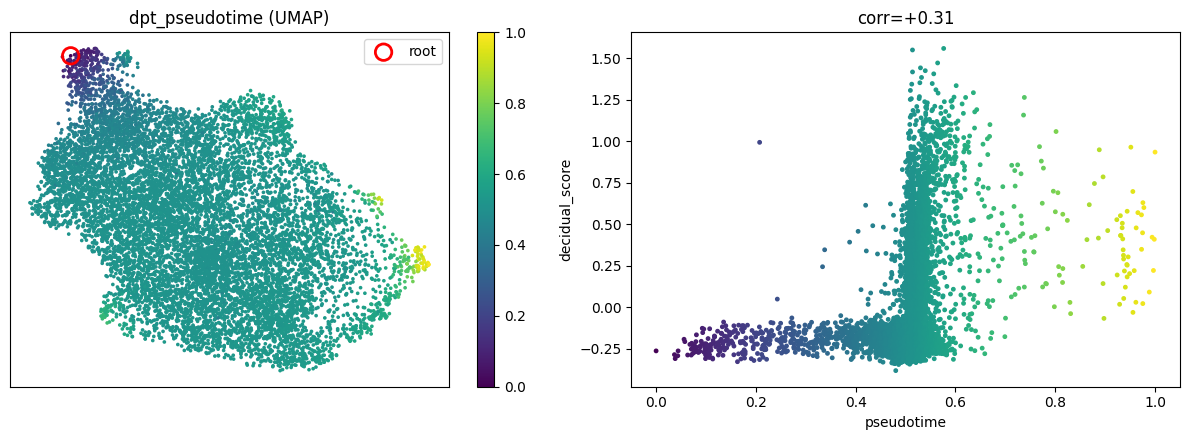

In [18]:
a.uns["iroot"] = root_ix
sc.tl.dpt(a)
print("dpt_pseudotime range:", float(a.obs["dpt_pseudotime"].min()), "->", float(a.obs["dpt_pseudotime"].max()))

# sanity: pt should increase with decidual_score if the root is the fibroblast end
r = np.corrcoef(a.obs["dpt_pseudotime"], a.obs["decidual_score"])[0,1]
print(f"corr(pseudotime, decidual_score) = {r:+.2f}   (want POSITIVE; strongly negative => flip ROOT_SIGN)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sc0 = ax[0].scatter(a.obsm["X_umap"][:,0], a.obsm["X_umap"][:,1], c=a.obs["dpt_pseudotime"],
                    s=7, cmap="viridis", linewidths=0)
ax[0].scatter(*a.obsm["X_umap"][root_ix], s=140, edgecolor="red", facecolor="none", lw=2, label="root")
ax[0].set_title("dpt_pseudotime (UMAP)"); ax[0].legend(); ax[0].set_xticks([]); ax[0].set_yticks([])
plt.colorbar(sc0, ax=ax[0])
ax[1].scatter(a.obs["dpt_pseudotime"], a.obs["decidual_score"], s=6, c=a.obs["dpt_pseudotime"], cmap="viridis")
ax[1].set_xlabel("pseudotime"); ax[1].set_ylabel("decidual_score"); ax[1].set_title(f"corr={r:+.2f}")
plt.tight_layout(); plt.show()

## 7. Spatial view (mouse, this timepoint)

Colored by pseudotime on the DBSCAN spatial coords. If `x_um_dbscan` isn't in this object, spatial
comes from wherever your pipeline stores coords — adjust the two column names.

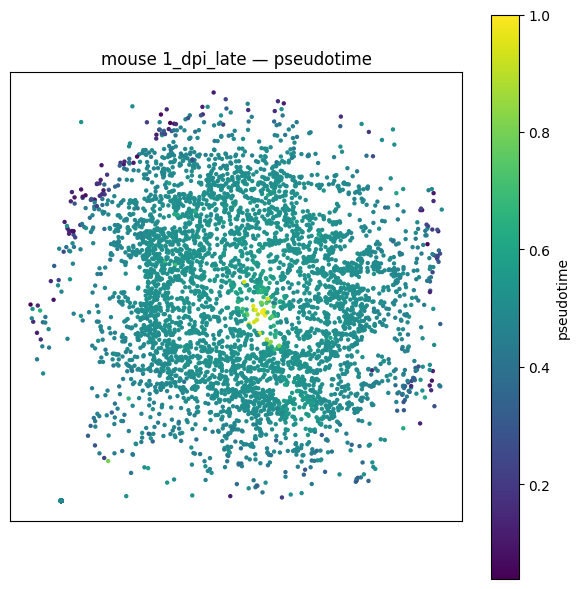

In [19]:
xcol, ycol = "x_um_dbscan", "y_um_dbscan"
have_xy = xcol in a.obs.columns and ycol in a.obs.columns
if not have_xy and "spatial" in a.obsm:
    xy = np.asarray(a.obsm["spatial"]); a.obs[xcol], a.obs[ycol] = xy[:,0], xy[:,1]; have_xy = True

if have_xy:
    m = np.isfinite(a.obs[xcol]) & np.isfinite(a.obs[ycol])
    fig, ax = plt.subplots(figsize=(6,6)); ax.set_facecolor("white")
    s = ax.scatter(a.obs[xcol][m], a.obs[ycol][m], c=a.obs["dpt_pseudotime"][m],
                   s=10, cmap="viridis", linewidths=0)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"mouse {TIMEPOINT} — pseudotime")
    plt.colorbar(s, ax=ax, label="pseudotime"); plt.tight_layout(); plt.show()
else:
    print(f"no spatial coords ({xcol}/{ycol} or obsm['spatial']) on this object — skipping spatial panel")

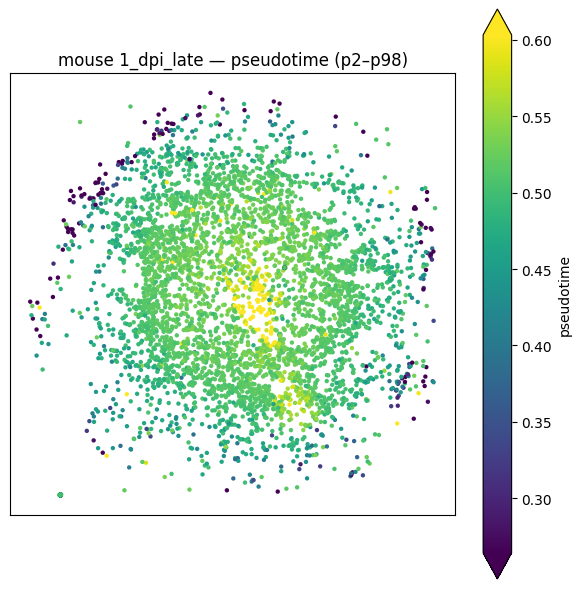

In [15]:
xcol, ycol = "x_um_dbscan", "y_um_dbscan"
have_xy = xcol in a.obs.columns and ycol in a.obs.columns
if not have_xy and "spatial" in a.obsm:
    xy = np.asarray(a.obsm["spatial"]); a.obs[xcol], a.obs[ycol] = xy[:,0], xy[:,1]; have_xy = True

if have_xy:
    m = (np.isfinite(a.obs[xcol]) & np.isfinite(a.obs[ycol])
         & np.isfinite(a.obs["dpt_pseudotime"])).values          # also drop NaN pt
    pt = a.obs["dpt_pseudotime"].values[m]
    vmin, vmax = np.percentile(pt, [2, 98])                        # 2nd–98th percentile clip

    fig, ax = plt.subplots(figsize=(6,6)); ax.set_facecolor("white")
    s = ax.scatter(a.obs[xcol].values[m], a.obs[ycol].values[m], c=pt,
                   s=10, cmap="viridis", vmin=vmin, vmax=vmax, linewidths=0)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"mouse {TIMEPOINT} — pseudotime (p2–p98)")
    plt.colorbar(s, ax=ax, label="pseudotime", extend="both")      # arrows flag clipped tails
    plt.tight_layout(); plt.show()
else:
    print(f"no spatial coords ({xcol}/{ycol} or obsm['spatial']) on this object — skipping spatial panel")

In [17]:
a.obs['fine_refined']

CCTCCAACAGCATGCC-1-1_dpi_late_mck12a      dec3
TGTGTGAGTAGCACGA-1-1_dpi_late_mck12a      dec3
TAAGTCGCACGTCGGT-1-1_dpi_late_mck12a      dec2
CCGCAAGTCATTCACT-1-1_dpi_late_mck12a      dec2
CATACTTCAAACGAGC-1-1_dpi_late_mck12a      dec2
                                         ...  
ACTCCCATCGCCTCTA-1-1_dpi_late_mck12b      dec2
CTACTATTCTGTGCTC-1-1_dpi_late_mck12b     eFib3
AGCATCACAATACGCT-1-1_dpi_late_mck12b    eFib2i
GGTAGAGTCGCAAGAG-1-1_dpi_late_mck12b    eFib2i
CTGAGCGGTTCGGTTA-1-1_dpi_late_mck12b    eFib2i
Name: fine_refined, Length: 10656, dtype: category
Categories (8, object): ['dec1', 'dec2', 'dec3', 'eFib1', 'eFib2', 'eFib2i', 'eFib3', 'eFibP']

## 8. Write the transfer-ready object

Contract `kara_rings_figure` reads: `obs_names` = **bare mouse barcodes** (matching `mm_cell_barcode`
in the joint) + a `dpt_pseudotime` column. We set obs_names from `cell_barcode` and write.

In [21]:
import numpy as np, pandas as pd

# 1) subtype ordering by the pseudotime you just computed (same check as on the object)
sub = a.obs['fine_refined'].astype(str)
g = (a.obs.assign(_s=sub).groupby('_s')['dpt_pseudotime']
       .agg(['mean','median','count']).sort_values('mean'))
g['kind'] = ['dec' if s.lower().startswith('dec')
             else ('fib' if 'fib' in s.lower() else '?') for s in g.index]
print(g.to_string())
fib, dec = g.loc[g.kind=='fib','mean'].mean(), g.loc[g.kind=='dec','mean'].mean()
print(f"\nmean pt: fib={fib:.3f} dec={dec:.3f} -> "
      f"{'OK (fib<dec)' if fib<dec else 'FLIPPED (dec<fib)'}")

# 2) WHICH diffusion component is the fib->dec axis (so you know ROOT_DC, not just the sign)
decid = np.array([1.0 if s.lower().startswith('dec') else 0.0 for s in sub])
print("\ncorr(DC_k, decidual identity)  — biggest |corr| = the trajectory axis, its sign -> ROOT_SIGN:")
for k in range(1, 6):
    print(f"  DC{k}: {np.corrcoef(a.obsm['X_diffmap'][:,k], decid)[0,1]:+.3f}")

# 3) the one-number orientation check (want clearly POSITIVE)
if 'decidual_score' in a.obs:
    r = np.corrcoef(a.obs['dpt_pseudotime'], a.obs['decidual_score'])[0,1]
    print(f"\ncorr(pseudotime, decidual_score) = {r:+.3f}  (positive=oriented right)")

            mean    median  count kind
_s                                    
eFib1   0.256842  0.231950    362  fib
eFib2i  0.488626  0.499332   3734  fib
eFib2   0.504154  0.505865    152  fib
eFibP   0.510039  0.515642    161  fib
dec2    0.521129  0.521553   3818  dec
dec1    0.521665  0.517243   1233  dec
eFib3   0.544659  0.535355    724  fib
dec3    0.615305  0.570640    472  dec

mean pt: fib=0.461 dec=0.553 -> OK (fib<dec)

corr(DC_k, decidual identity)  — biggest |corr| = the trajectory axis, its sign -> ROOT_SIGN:
  DC1: +0.484
  DC2: +0.368
  DC3: -0.531
  DC4: +0.159
  DC5: +0.102

corr(pseudotime, decidual_score) = +0.315  (positive=oriented right)


In [22]:
out = a.copy()
if "cell_barcode" in out.obs.columns:
    out.obs_names = out.obs["cell_barcode"].astype(str).values      # bare barcodes for the join
    if not out.obs_names.is_unique:
        print("WARN: bare barcodes not unique (multi-sample timepoint) — join uses first; "
              "kara_rings_figure's _core() fallback also strips suffixes")
else:
    print("WARN: no 'cell_barcode' col — leaving obs_names as-is; check the join rate downstream")

keep_cols = ["dpt_pseudotime","decidual_score","apop_score",FINE_COL,COARSE_COL,TP_COL,"cell_barcode"]
out.obs = out.obs[[c for c in keep_cols if c in out.obs.columns]].copy()
out.write_h5ad(OUT_H5AD)
print("wrote", OUT_H5AD, out.shape, "| dpt in obs:", "dpt_pseudotime" in out.obs.columns)

WARN: bare barcodes not unique (multi-sample timepoint) — join uses first; kara_rings_figure's _core() fallback also strips suffixes
wrote /n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/pseudotime/adata_1dpi.h5ad (10656, 33698) | dpt in obs: True


## Next: transfer to human

This object plugs straight into `kara_rings_figure` (it reads `adata_<STAGE_TAG>.h5ad`, joins
`dpt_pseudotime` onto the joint object by mouse barcode, and `project()`s it onto human). Or add a
`transferred_pseudotime` column to `make_transferred_object.py` using the same `project()` on this
`dpt_pseudotime`. Re-run this notebook per timepoint (change `TIMEPOINT`/`STAGE_TAG` in config).